# Imports

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"
import keras
import torch

In [2]:
import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.metrics
import sklearn.model_selection
import tqdm.notebook as tqdm
from transformers import AutoTokenizer, Qwen2TokenizerFast

# Dataset

Load the dataset (we will be using [imdb](https://huggingface.co/datasets/stanfordnlp/imdb)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset.

In [3]:
train_dataset: datasets.Dataset = datasets.load_dataset('stanfordnlp/imdb', split='train')
test_dataset: datasets.Dataset = datasets.load_dataset('stanfordnlp/imdb', split='test')

In [4]:
train_df: pd.DataFrame = train_dataset.to_pandas()
test_df: pd.DataFrame = test_dataset.to_pandas()

In [5]:
train_df

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


In [6]:
test_df

,text,label
0,I love sci-fi and am willing to put up with a ...,0
1,"Worth the entertainment value of a rental, esp...",0
2,its a totally average film with a few semi-alr...,0
3,STAR RATING: ***** Saturday Night **** Friday ...,0
4,"First off let me say, If you haven't enjoyed a...",0
...,...,...
24995,Just got around to seeing Monster Man yesterda...,1
24996,I got this as part of a competition prize. I w...,1
24997,I got Monster Man in a box set of three films ...,1
24998,"Five minutes in, i started to feel how naff th...",1


In [7]:
train_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [8]:
test_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

# Tokenizer

Train your own tokenizer on an English corpus or load a pretrained tokenizer for English sentences (see the one used in class)

In [9]:
import string

from tokenizers import Tokenizer
from tokenizers.models import WordPiece
from tokenizers.normalizers import BertNormalizer
from tokenizers.pre_tokenizers import BertPreTokenizer
from tokenizers.processors import TemplateProcessing
from tokenizers.trainers import WordPieceTrainer
from transformers import PreTrainedTokenizerFast

In [10]:
texts = train_df["text"]


tokenizer = Tokenizer(WordPiece(unk_token="[UNK]", continuing_subword_prefix="##"))

tokenizer.normalizer = BertNormalizer(lowercase=True, strip_accents=True)

tokenizer.pre_tokenizer = BertPreTokenizer()


alphabet = list(string.ascii_lowercase + string.digits + string.punctuation)

special_tokens = ["[UNK]", "[PAD]", "[CLS]", "[SEP]"]

trainer = WordPieceTrainer(
    vocab_size=4000,
    min_frequency=2,
    special_tokens=special_tokens,
    initial_alphabet=alphabet,
    continuing_subword_prefix="##",
)

tokenizer.train_from_iterator(texts, trainer=trainer)

vocab = tokenizer.get_vocab()

tokenizer.post_processor = TemplateProcessing(
    single="[CLS] $A [SEP]",
    pair="[CLS] $A [SEP] $B:1 [SEP]:1",
    special_tokens=[("[CLS]", vocab["[CLS]"]), ("[SEP]", vocab["[SEP]"])],
)


tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=tokenizer,
    unk_token="[UNK]",
    pad_token="[PAD]",
    cls_token="[CLS]",
    sep_token="[SEP]",
)

tokenizer.save_pretrained("../../model_checkpoints/tokenizer/imdb_wordpiece")

('../../model_checkpoints/tokenizer/imdb_wordpiece\\tokenizer_config.json',
 '../../model_checkpoints/tokenizer/imdb_wordpiece\\special_tokens_map.json',
 '../../model_checkpoints/tokenizer/imdb_wordpiece\\tokenizer.json')

In [11]:
tokenizer("Hello, world!", add_special_tokens=False)["input_ids"]

[1659, 106, 15, 744, 4]

## Dataset tokenization

In [12]:
train_tokens: list[list[int]] = tokenizer(list(train_dataset["text"]), add_special_tokens=False)["input_ids"]
test_tokens: list[list[int]] = tokenizer(list(test_dataset["text"]), add_special_tokens=False)["input_ids"]

In [13]:
train_tokens_len = [len(tokens) for tokens in train_tokens]
test_tokens_len = [len(tokens) for tokens in test_tokens]

<Axes: ylabel='Count'>

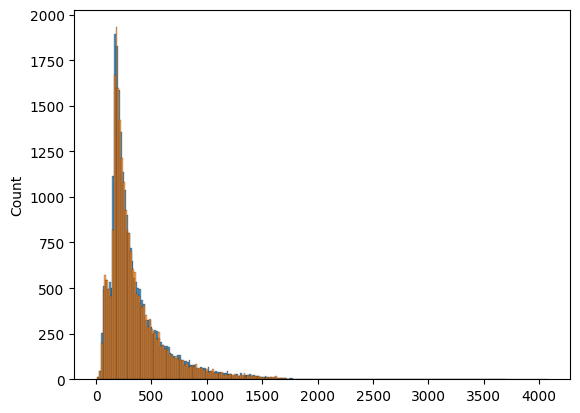

In [14]:
sns.histplot(train_tokens_len)
sns.histplot(test_tokens_len, alpha=0.7)

In [15]:
np.quantile(train_tokens_len, 0.99), np.quantile(test_tokens_len, 0.99)

(np.float64(1417.0), np.float64(1401.0))

In [16]:
np.quantile(train_tokens_len, 0.95), np.quantile(test_tokens_len, 0.95)

(np.float64(943.0), np.float64(919.0))

In [17]:
def truncate_sequence(sequence, max_length):
    if max_length is not None and len(sequence) > max_length:
        return sequence[0 : int(max_length * 0.7)] + sequence[-int(max_length * 0.3) :]
    return sequence

In [18]:
class SequenceDataset(keras.utils.PyDataset):
    def __init__(
        self,
        x,
        y,
        tokenizer,
        max_seq_length: int,
        fixed_seq_length: bool,
        batch_size: int = 128,
        shuffle: bool = True,
        rng: np.random.Generator | None = None,
        **kwargs,
    ):
        super().__init__(**kwargs)
        if rng is None:
            rng = np.random.default_rng()

        self.rng = rng
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.max_seq_length = max_seq_length
        self.fixed_seq_length = fixed_seq_length
        self.tokenizer = tokenizer

        self.raw_text_tokens = [truncate_sequence(seq, self.max_seq_length) for seq in x]
        self.y = np.array(y)

        if fixed_seq_length:
            self.padded_text_tokens = self.pad_sequences(
                self.raw_text_tokens, maxlen=max_seq_length
            )

        self.batch_order: list[np.ndarray] = []
        self.on_epoch_end()

    @classmethod
    def pad_sequences(cls, x, maxlen) -> np.ndarray:
        return keras.utils.pad_sequences(
            x,
            maxlen=maxlen,
            padding="post",
            truncating="post",
            value=tokenizer.pad_token_id,
        )

    def __len__(self):
        return len(self.batch_order)

    def __getitem__(self, idx):
        batch_indices = self.batch_order[idx]

        if not self.fixed_seq_length:
            text_tokens = [self.raw_text_tokens[i] for i in batch_indices]
            max_len = max(len(tokens) for tokens in text_tokens)
            x = self.pad_sequences(text_tokens, maxlen=max_len)
        else:
            x = self.padded_text_tokens[batch_indices]

        return x, self.y[batch_indices]

    def on_epoch_end(self):
        n = len(self.raw_text_tokens)
        if n == 0:
            self.batch_order = []
            return

        boundaries = list(range(0, n, self.batch_size)) + [n]

        if self.fixed_seq_length:
            if self.shuffle:
                indices = self.rng.permutation(n)
            else:
                indices = np.arange(n)
        else:
            lengths = np.array([len(t) for t in self.raw_text_tokens])
            if self.shuffle:
                jitter = self.rng.random(n)
                indices = np.lexsort((jitter, lengths))
            else:
                indices = np.argsort(lengths, kind="stable")

        batches = [
            indices[boundaries[i] : boundaries[i + 1]]
            for i in range(len(boundaries) - 1)
        ]

        if self.shuffle and not self.fixed_seq_length:
            self.rng.shuffle(batches)

        self.batch_order = batches

In [47]:
train_ds = SequenceDataset(
    train_tokens,
    list(train_dataset["label"]),
    tokenizer,
    max_seq_length=256,
    fixed_seq_length=False,
    batch_size=32,
)

In [48]:
test_ds = SequenceDataset(
    test_tokens,
    list(test_dataset["label"]),
    tokenizer,
    max_seq_length=256,
    fixed_seq_length=False,
    batch_size=32,
    shuffle=False
)

In [49]:
batches_positive_counts = [(tokens.shape[-1], sum(labels)) for tokens, labels in train_ds]
x_vals, y_vals = zip(*batches_positive_counts)

<Axes: >

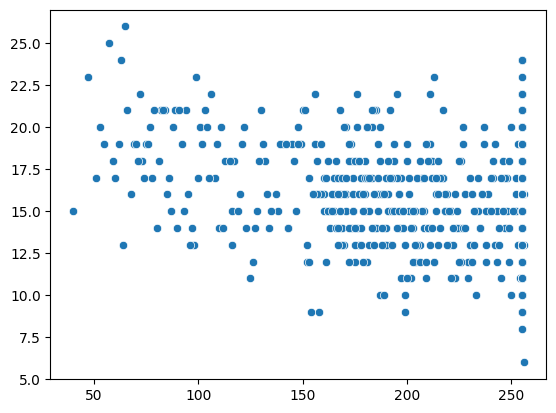

In [50]:
sns.scatterplot(x=x_vals, y=y_vals)

In [51]:
np.corrcoef(x_vals, y_vals)

array([[ 1.        , -0.18868247],
       [-0.18868247,  1.        ]])

# Model

Implement your model. The model should have the Transformer architecture. Remember to mask out padding tokens.

In [52]:
@keras.saving.register_keras_serializable()
class TokenAndPositionEmbedding(keras.layers.Layer):
    def __init__(
        self, maxlen: int, vocab_size: int, embed_dim: int, pad_token_id: int,**kwargs
    ):
        super().__init__(**kwargs)
        self.supports_masking = True

        self.maxlen = maxlen
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.pad_token_id = pad_token_id

        self.token_emb = keras.layers.Embedding(vocab_size, embed_dim, mask_zero=False)
        self.pos_emb = keras.layers.Embedding(maxlen, embed_dim)
        self.pad_token_id = pad_token_id
        self.cls_token = self.add_weight(
            shape=(1, 1, embed_dim),
            initializer="random_normal",
            trainable=True,
            name="cls_token",
        )

    def call(self, x):
        seq_len = keras.ops.shape(x)[1]
        positions = keras.ops.arange(seq_len, dtype="int32")
        positions = keras.ops.expand_dims(positions, 0)

        x_emb = self.token_emb(x) + self.pos_emb(positions)

        batch_size = keras.ops.shape(x)[0]
        cls_tokens = keras.ops.broadcast_to(
            self.cls_token, (batch_size, 1, self.embed_dim)
        )
        x_emb = keras.ops.concatenate([cls_tokens, x_emb], axis=1)
        return x_emb

    def compute_mask(self, inputs, previous_mask=None):
        token_mask = keras.ops.not_equal(inputs, self.pad_token_id)

        cls_mask = keras.ops.ones_like(token_mask[:, :1])

        combined_mask = keras.ops.concatenate([cls_mask, token_mask], axis=1)
        return combined_mask

    def get_config(self):
        return {
            "maxlen": self.maxlen,
            "vocab_size": self.vocab_size,
            "embed_dim": self.embed_dim,
            "pad_token_id": self.pad_token_id,
            **super().get_config(),
        }

In [53]:
def transformer_block(
    x, embedding_size, num_heads, block_features, dropout, block_name
):
    h = keras.layers.LayerNormalization(epsilon=1e-6, name=block_name + "_ln_1")(x)
    h, attention_score = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embedding_size // num_heads,
        dropout=dropout,
        name=block_name + "_attention",
    )(h, h, return_attention_scores=True)
    h = keras.layers.Dropout(dropout, name=block_name + "_do_1")(h)
    x = keras.layers.Add(name=block_name + "_add_1")([x, h])

    h = keras.layers.LayerNormalization(epsilon=1e-6, name=block_name + "_ln_2")(x)
    h = keras.layers.Dense(
        block_features, activation="gelu", name=block_name + "_dense_1"
    )(h)
    h = keras.layers.Dense(embedding_size, name=block_name + "_dense_2")(h)
    h = keras.layers.Dropout(dropout, name=block_name + "_do_2")(h)
    x = keras.layers.Add(name=block_name + "_add_2")([x, h])
    return x, attention_score

In [54]:
def get_model(
    vocab_size: int,
    embedding_size: int,
    max_length: int,
    num_blocks: int,
    num_heads: int,
    pad_token_id: int,
    name: str | None = None,
) -> keras.Model:
    """Creates a model with Transformer architecture for binary sequence classification.

    Arguments:
        vocab_size: size of the tokenizer vocabulary
        embedding_size: size of the internal mdoel representations
        max_length: maximal allowed sequence length
        num_blocks: number of transformer blocks
        num_heads: number of multi head attentions heads
        pad_token_id: id of the padding token
        name: the model name

    Returns:
        The model"""
    tokens = keras.layers.Input(shape=(None,), dtype="int32", name="tokens")

    x = TokenAndPositionEmbedding(
        max_length, vocab_size, embedding_size, pad_token_id, name="embedding"
    )(tokens)
    x = keras.layers.Dropout(0.1, name="do_0")(x)

    attention_scores = []
    for i in range(num_blocks):
        x, att_score = transformer_block(
            x, embedding_size, num_heads, 256, 0.1, block_name=f"transformer_block_{i}"
        )
        attention_scores.append(att_score)

    x = keras.layers.LayerNormalization(epsilon=1e-6, name="ln")(x)
    cls = x[:, 0, :]
    x = keras.layers.Dense(128, activation="gelu", name="dense_1")(cls)
    x = keras.layers.Dropout(0.1, name="do_1")(x)
    out = keras.layers.Dense(1, activation="sigmoid", name="dense_2")(x)

    return keras.Model(inputs=tokens, outputs=[out] + attention_scores, name=name)

# Training

Train the model. Choose model size, batch size, loss, learning rate schedule.

In [55]:
full_model = get_model(
    vocab_size=tokenizer.vocab_size,
    pad_token_id=tokenizer.pad_token_id,
    embedding_size=256,
    max_length=train_ds.max_seq_length,
    num_blocks=4,
    num_heads=4,
    name="transformer",
)

In [56]:
model = keras.Model(
    inputs=full_model.input,
    outputs=full_model.outputs[0],
    name="classifier"
)

attention_model = keras.Model(
    inputs=full_model.input,
    outputs=full_model.outputs[1:],
    name="attention_extractor"
)

In [57]:
model.summary()

Model: "classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 256) │  1,089,792 │ tokens[0][0]      │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ do_0 (Dropout)      │ (None, None, 256) │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │        512 │ do_0[0][0]        │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ [(None, None,     │    263,168 │ transformer_bloc… │
│ (MultiHeadAttentio… │ 256), (None, 4,   │            │ transformer_bloc… │
│                     │ None, None)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │          0 │ transformer_bloc… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │          0 │ do_0[0][0],       │
│ (Add)               │                   │            │ transformer_bloc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │        512 │ transformer_bloc… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │     65,792 │ transformer_bloc… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │     65,792 │ transformer_bloc… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │          0 │ transformer_bloc… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │          0 │ transformer_bloc… │
│ (Add)               │                   │            │ transformer_bloc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │        512 │ transformer_bloc… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ [(None, None,     │    263,168 │ transformer_bloc… │
│ (MultiHeadAttentio… │ 256), (None, 4,   │            │ transformer_bloc… │
│                     │ None, None)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │          0 │ transformer_bloc… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │          0 │ transformer_bloc… │
│ (Add)               │                   │            │ transformer_bloc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_… │ (None, None, 256) │        512 │ transformer_bloc

 Total params: 2,706,433 (10.32 MB)

 Trainable params: 2,706,433 (10.32 MB)

 Non-trainable params: 0 (0.00 B)

In [58]:
model.compile(
    optimizer=keras.optimizers.AdamW(5e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", "auc"],
)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=2,
        restore_best_weights=True,
        verbose=1,
    )
]

In [60]:
model.fit(train_ds, validation_data=test_ds, epochs=10, callbacks=callbacks)

Epoch 1/10


782/782 ━━━━━━━━━━━━━━━━━━━━ 134s 171ms/step - accuracy: 0.7463 - auc: 0.8400 - loss: 0.4877 - val_accuracy: 0.8503 - val_auc: 0.9291 - val_loss: 0.3469
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 158s 202ms/step - accuracy: 0.8681 - auc: 0.9400 - loss: 0.3131 - val_accuracy: 0.8594 - val_auc: 0.9393 - val_loss: 0.3289
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 221s 283ms/step - accuracy: 0.8881 - auc: 0.9549 - loss: 0.2712 - val_accuracy: 0.8646 - val_auc: 0.9400 - val_loss: 0.3181
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 247s 316ms/step - accuracy: 0.9004 - auc: 0.9622 - loss: 0.2477 - val_accuracy: 0.8604 - val_auc: 0.9382 - val_loss: 0.3580
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 222s 285ms/step - accuracy: 0.9054 - auc: 0.9666 - loss: 0.2330 - val_accuracy: 0.8591 - val_auc: 0.9370 - val_loss: 0.3415
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 3.


# Evaluation

Evaluate the model you trained on the test dataset. Plot the ROC curve.

In [61]:
y_pred = model.predict(test_ds)

782/782 ━━━━━━━━━━━━━━━━━━━━ 80s 102ms/step


In [62]:
labels = [i for batch in test_ds for i in batch[1]]

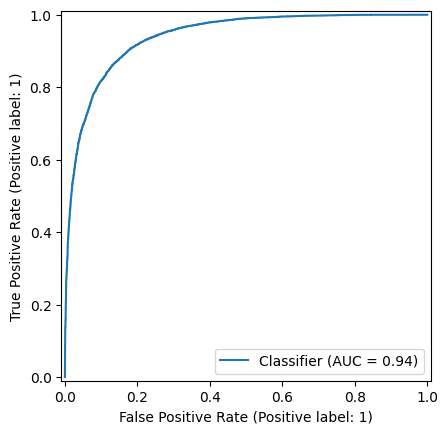

In [63]:
sklearn.metrics.RocCurveDisplay.from_predictions(labels, y_pred)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [64]:
def label_text(
    text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None
) -> int:
    """Computes the model output for `text` and outputs the predicted label

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization

    Return:
        Predicted label"""
    raw_tokens = tokenizer.encode(text, add_special_tokens=False)
    tokens = truncate_sequence(raw_tokens, max_length)

    prediction = model.predict(np.array([tokens]), verbose=False)
    label = int(prediction[0][0] > threshold)
    print("Probability:", prediction[0][0])
    print("Label      :", ["negative", "positive"][label])

    return label

In [65]:
reviews = {
    0: [
        "A dull mess. Wooden acting, predictable twist, and CGI that looks like a 2005 video game. Skip it.",
        "Two hours of my life wasted. The plot makes no sense, the jokes fall flat, and the villain is a cardboard cutout.",
        "Terrible pacing, awful dialogue, and a soundtrack that never shuts up. Even the explosions are boring.",
    ],
    1: [
        "A gripping thriller. Sharp writing, intense performances, and a finale that left me breathless. Highly recommend.",
        "Charming and heartfelt. The cast has great chemistry, the humor lands, and the emotional beats feel earned. A joy to watch.",
        "Visually stunning and deeply moving. The director crafts a rich world, and the lead performance is Oscar-worthy. Don't miss it.",
    ],
}


In [66]:
for key, texts in reviews.items():
    for text in texts:
        print(text)
        pred = label_text(text, model)
        if pred == key:
            print("✅Correct")
        else:
            print("❌Wrong")
        print()

A dull mess. Wooden acting, predictable twist, and CGI that looks like a 2005 video game. Skip it.
Probability: 0.0021932893
Label      : negative
✅Correct

Two hours of my life wasted. The plot makes no sense, the jokes fall flat, and the villain is a cardboard cutout.
Probability: 0.004871757
Label      : negative
✅Correct

Terrible pacing, awful dialogue, and a soundtrack that never shuts up. Even the explosions are boring.
Probability: 0.0023449366
Label      : negative
✅Correct

A gripping thriller. Sharp writing, intense performances, and a finale that left me breathless. Highly recommend.
Probability: 0.99333704
Label      : positive
✅Correct

Charming and heartfelt. The cast has great chemistry, the humor lands, and the emotional beats feel earned. A joy to watch.
Probability: 0.99327236
Label      : positive
✅Correct

Visually stunning and deeply moving. The director crafts a rich world, and the lead performance is Oscar-worthy. Don't miss it.
Probability: 0.9916853
Label     

In [67]:
reviews_ru = {
    0: [
        "Унылый бардак. Деревянная игра актёров, предсказуемый поворот и CGI, будто из видеоигры 2005 года. Пропускайте",
        "Два часа жизни зря. Сюжет не имеет смысла, шутки не срабатывают, а злодей — картонный",
        "Ужасный темп, отвратительные диалоги и саундтрек, который не замолкает. Даже взрывы скучные",
    ],
    1: [
        "Захватывающий триллер. Острая сценарная работа, мощная игра актёров и финал, от которого захватывает дух. Очень рекомендую",
        "Очаровательно и душевно. У актёров отличная химия, юмор попадает в цель, а эмоциональные моменты искренни. Смотреть — одно удовольствие",
        "Визуально потрясающе и глубоко трогательно. Режиссёр создаёт богатый мир, а главная роль достойна „Оскара“. Не пропустите",
    ],
}


In [68]:
for key, texts in reviews_ru.items():
    for text in texts:
        print(text)
        pred = label_text(text, model)
        print()

Унылый бардак. Деревянная игра актёров, предсказуемый поворот и CGI, будто из видеоигры 2005 года. Пропускайте
Probability: 0.15974095
Label      : negative

Два часа жизни зря. Сюжет не имеет смысла, шутки не срабатывают, а злодей — картонный
Probability: 0.162464
Label      : negative

Ужасный темп, отвратительные диалоги и саундтрек, который не замолкает. Даже взрывы скучные
Probability: 0.14283988
Label      : negative

Захватывающий триллер. Острая сценарная работа, мощная игра актёров и финал, от которого захватывает дух. Очень рекомендую
Probability: 0.13910547
Label      : negative

Очаровательно и душевно. У актёров отличная химия, юмор попадает в цель, а эмоциональные моменты искренни. Смотреть — одно удовольствие
Probability: 0.46369612
Label      : negative

Визуально потрясающе и глубоко трогательно. Режиссёр создаёт богатый мир, а главная роль достойна „Оскара“. Не пропустите
Probability: 0.51992977
Label      : positive



# Bonus

Inspect the model attention scores with respect to words and punctuation in the sentence. What does the model consider when classifying the sentence.

In [69]:

def attention_heatmap(
    text: str,
    attention_model: keras.Model,
    block_idx: int = 0,
    max_length: int = 256,
):
    sample = tokenizer.encode(text, add_special_tokens=False)
    sample = truncate_sequence(sample, max_length)

    tokens = tokenizer.convert_ids_to_tokens(sample)

    scores = attention_model.predict(
        np.array([sample]),
        verbose=False
    )[block_idx][0]

    num_heads = scores.shape[0]

    cls_attention = scores[:, 0, 1:]

    fig, axes = plt.subplots(
        num_heads,
        1,
        figsize=(max(12, len(tokens) * 0.5), num_heads),
        sharex=True,
        squeeze=False,
    )

    for i in range(num_heads):
        sns.heatmap(
            cls_attention[i:i+1, :],
            cmap="viridis",
            xticklabels=tokens,
            yticklabels=False,
            ax=axes[i, 0],
            cbar=True,
        )

        axes[i, 0].set_ylabel(f"Head {i}")
        axes[i, 0].set_yticks([])

    axes[-1, 0].set_xlabel("Tokens")
    axes[-1, 0].tick_params(axis="x", rotation=60)

    fig.suptitle(
        f"CLS Attention — Transformer Block {block_idx}",
        y=1.01,
    )

    plt.tight_layout()
    plt.show()

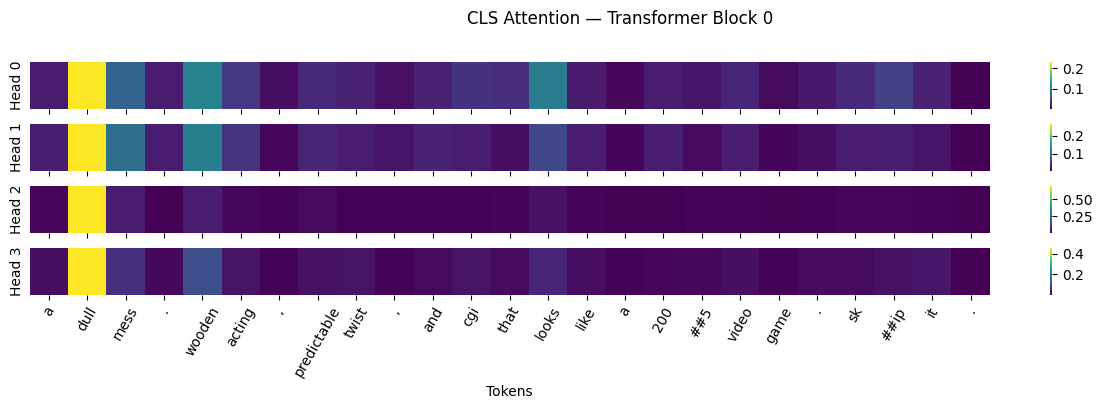

In [70]:
text = "A dull mess. Wooden acting, predictable twist, and CGI that looks like a 2005 video game. Skip it."
attention_heatmap(text, attention_model, block_idx=0)

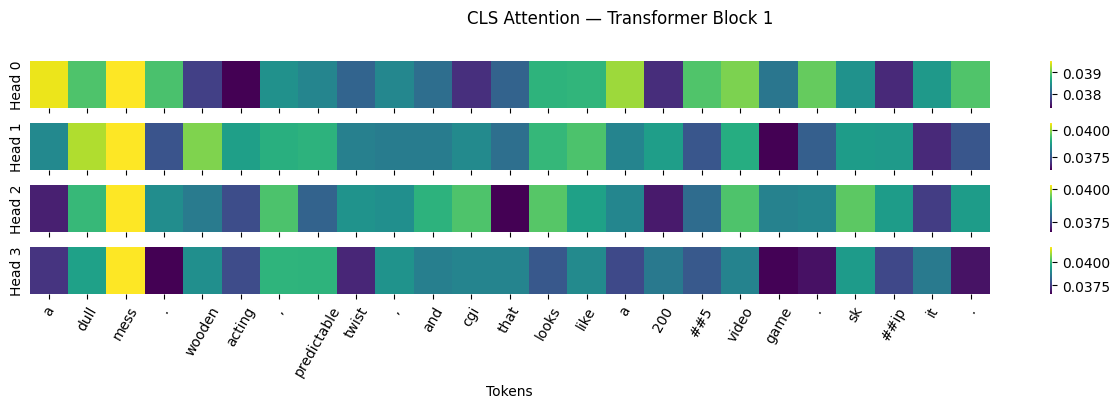

In [71]:
attention_heatmap(text, attention_model, block_idx=1)

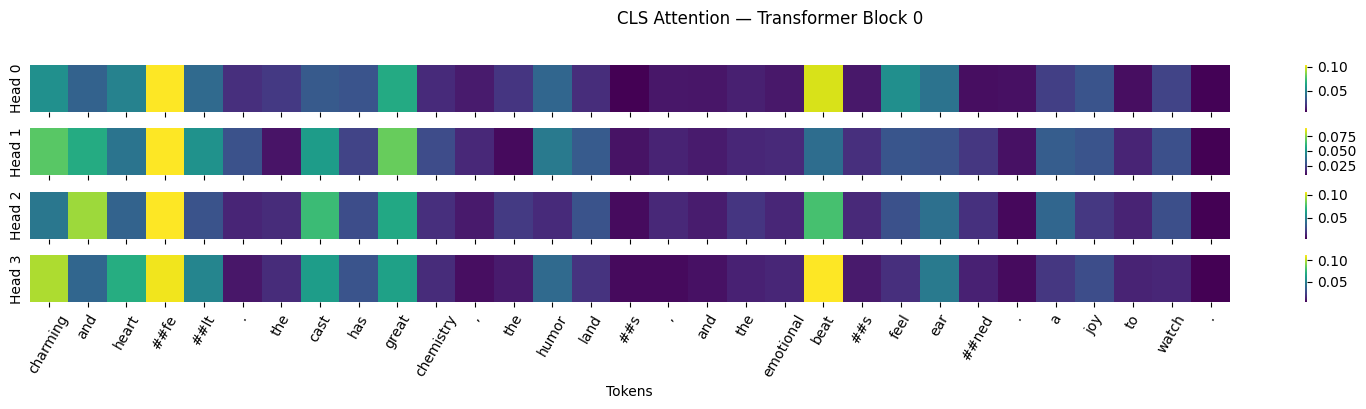

In [72]:
text = "Charming and heartfelt. The cast has great chemistry, the humor lands, and the emotional beats feel earned. A joy to watch."
attention_heatmap(text, attention_model, block_idx=0)

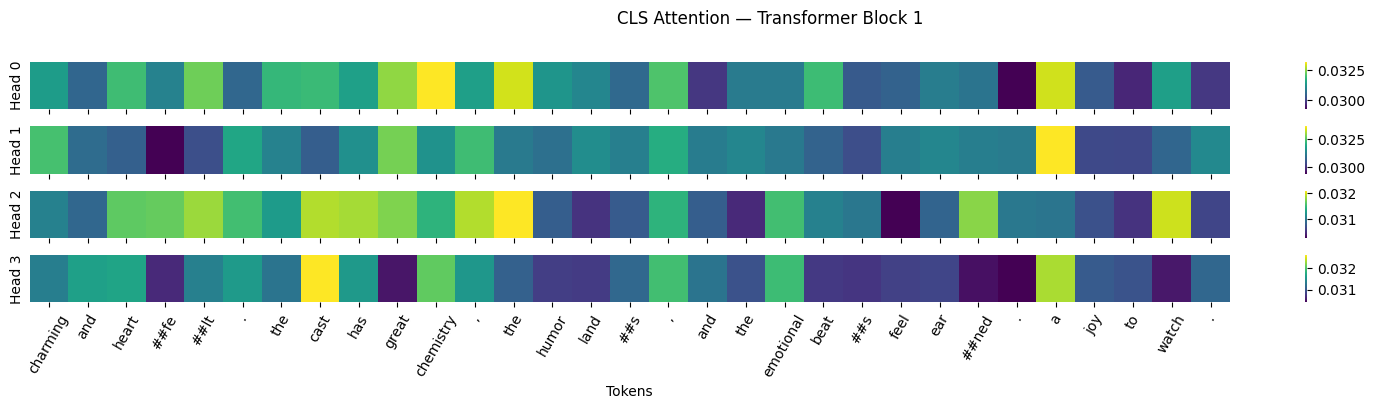

In [73]:
attention_heatmap(text, attention_model, block_idx=1)